<a href="https://colab.research.google.com/github/Avinash2567/Avinash2567/blob/main/svmnonlinear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

print("Uploaded file:", filename)

if filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename, header=None)
else:
    # Most downloadable MAGIC datasets are CSV or text files.
    try:
        df = pd.read_csv(filename, sep=None, engine="python")
        # If the file has no header, reload without one.
        if df.shape[1] == 1:
            df = pd.read_csv(filename, header=None, sep=None, engine="python")
    except Exception:
        df = pd.read_csv(filename, header=None)

print("Dataset loaded!")
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Saving telescope_data.csv to telescope_data (1).csv
Uploaded file: telescope_data (1).csv
Dataset loaded!
Shape: (19020, 12)


,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


Columns: ['Unnamed: 0', 'fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']


In [2]:
# Detect the target column
possible_targets = ["class", "Class", "target", "label", "Label"]

target_column = next(
    (col for col in possible_targets if col in df.columns),
    df.columns[-1]
)

print("Target column:", target_column)
print("Target values:")
print(df[target_column].value_counts())

# Separate input features and target
X = df.drop(columns=[target_column]).copy()
y = df[target_column].astype(str).str.strip().str.lower()

# Convert features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove rows containing missing or invalid data
valid_rows = X.notna().all(axis=1) & y.isin(["g", "h"])
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

# Encode gamma as 1 and hadron as 0
y = y.map({"g": 1, "h": 0})

print("\nCleaned dataset shape:", X.shape)
print("Class distribution:")
print(y.value_counts().rename(index={1: "Gamma", 0: "Hadron"}))

if X.shape[1] != 10:
    print("Warning: Expected 10 features in the standard MAGIC dataset.")

if len(X) == 0:
    raise ValueError(
        "No valid rows found. Check the target column and its class labels."
    )

Target column: class
Target values:
class
g    12332
h     6688
Name: count, dtype: int64

Cleaned dataset shape: (19020, 11)
Class distribution:
class
Gamma     12332
Hadron     6688
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 15216
Testing samples: 3804
Number of features: 11


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

rbf_svm.fit(X_train, y_train)

print("Non-Linear SVM trained successfully!")

Non-Linear SVM trained successfully!


In [5]:
y_pred = rbf_svm.predict(X_test)

print("Actual labels:     ", y_test.to_numpy()[:15])
print("Predicted labels:  ", y_pred[:15])

Actual labels:      [1 1 1 1 0 0 1 0 0 1 1 0 1 1 0]
Predicted labels:   [1 1 1 1 0 0 1 0 0 1 1 0 1 1 0]


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:  {:.2f}%".format(
    accuracy_score(y_test, y_pred) * 100
))

print("Precision: {:.2f}%".format(
    precision_score(y_test, y_pred, zero_division=0) * 100
))

print("Recall:    {:.2f}%".format(
    recall_score(y_test, y_pred, zero_division=0) * 100
))

print("F1-score:  {:.2f}%".format(
    f1_score(y_test, y_pred, zero_division=0) * 100
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Hadron", "Gamma"],
    zero_division=0
))

print("ROC-AUC: {:.4f}".format(
    roc_auc_score(y_test, rbf_svm.decision_function(X_test))
))

Accuracy:  99.34%
Precision: 99.47%
Recall:    99.51%
F1-score:  99.49%

Classification Report:
              precision    recall  f1-score   support

      Hadron       0.99      0.99      0.99      1338
       Gamma       0.99      1.00      0.99      2466

    accuracy                           0.99      3804
   macro avg       0.99      0.99      0.99      3804
weighted avg       0.99      0.99      0.99      3804

ROC-AUC: 0.9998


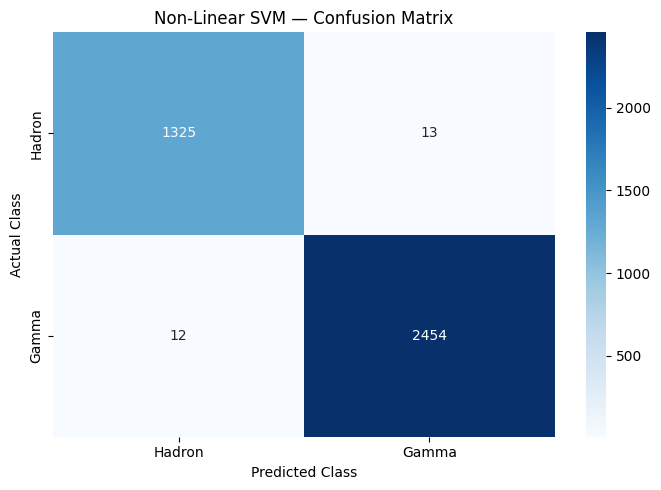

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Hadron", "Gamma"],
    yticklabels=["Hadron", "Gamma"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Non-Linear SVM — Confusion Matrix")
plt.tight_layout()
plt.show()

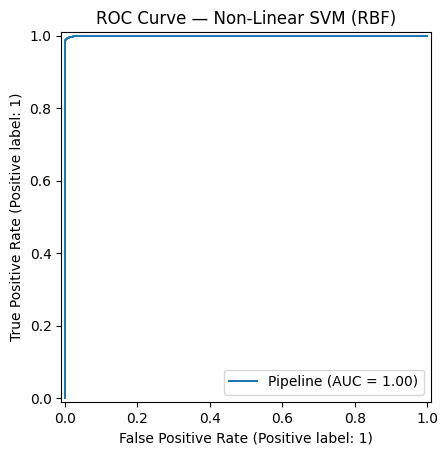

In [8]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    rbf_svm,
    X_test,
    y_test,
    pos_label=1
)

plt.title("ROC Curve — Non-Linear SVM (RBF)")
plt.show()

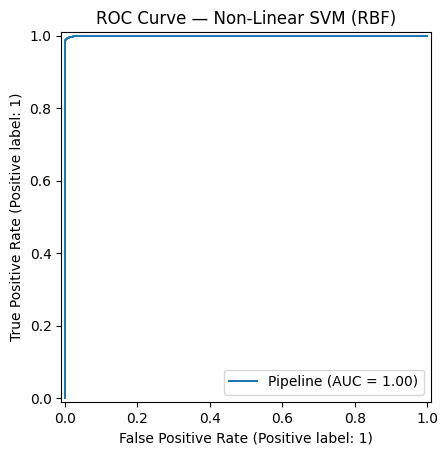

In [9]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    rbf_svm,
    X_test,
    y_test,
    pos_label=1
)

plt.title("ROC Curve — Non-Linear SVM (RBF)")
plt.show()

Variance retained: 55.20%


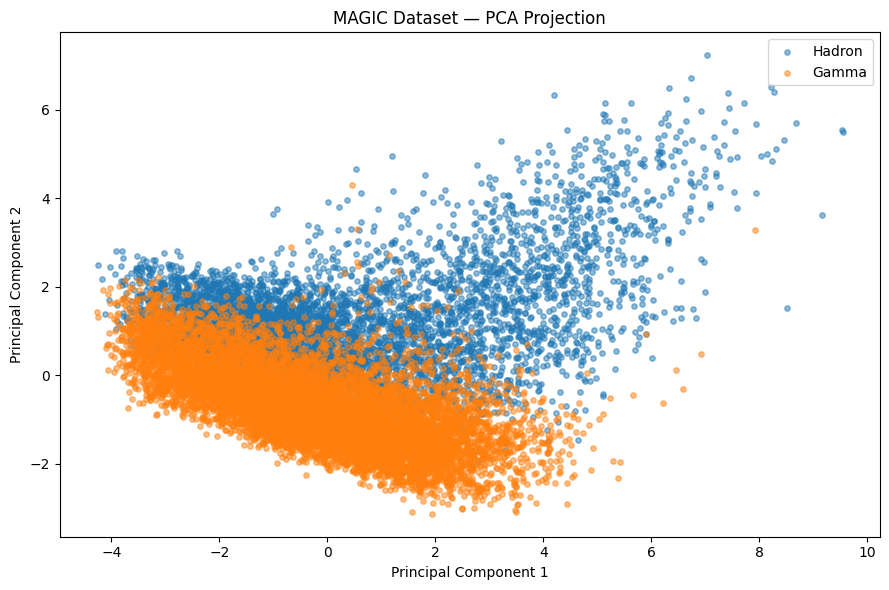

In [10]:
from sklearn.decomposition import PCA

# Fit scaling and PCA on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Variance retained: {:.2f}%".format(
    pca.explained_variance_ratio_.sum() * 100
))

plt.figure(figsize=(9, 6))

for label, name in [(0, "Hadron"), (1, "Gamma")]:
    mask = y_train.to_numpy() == label

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        label=name,
        alpha=0.5,
        s=15
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("MAGIC Dataset — PCA Projection")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
results = pd.DataFrame({
    "Actual": y_test.map({0: "Hadron", 1: "Gamma"}).to_numpy(),
    "Predicted": pd.Series(y_pred).map(
        {0: "Hadron", 1: "Gamma"}
    ).to_numpy()
})

results.to_csv("svm_predictions.csv", index=False)

print("Predictions saved successfully!")
files.download("svm_predictions.csv")

Predictions saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>